Dataset loaded successfully!
   Tweet_ID        Username  \
0         1         julie81   
1         2   richardhester   
2         3  williamsjoseph   
3         4     danielsmary   
4         5      carlwarren   

                                                Text  Retweets  Likes  \
0  Party least receive say or single. Prevent pre...         2     25   
1  Hotel still Congress may member staff. Media d...        35     29   
2  Nice be her debate industry that year. Film wh...        51     25   
3  Laugh explain situation career occur serious. ...        37     18   
4  Involve sense former often approach government...        27     80   

             Timestamp  
0  2023-01-30 11:00:51  
1  2023-01-02 22:45:58  
2  2023-01-18 11:25:19  
3  2023-04-10 22:06:29  
4  2023-01-24 07:12:21  

Columns: Index(['Tweet_ID', 'Username', 'Text', 'Retweets', 'Likes', 'Timestamp'], dtype='object')

Using column: Text

Tokenized Tweets:
[['party', 'least', 'receive', 'say', 'or', 'single', 'p

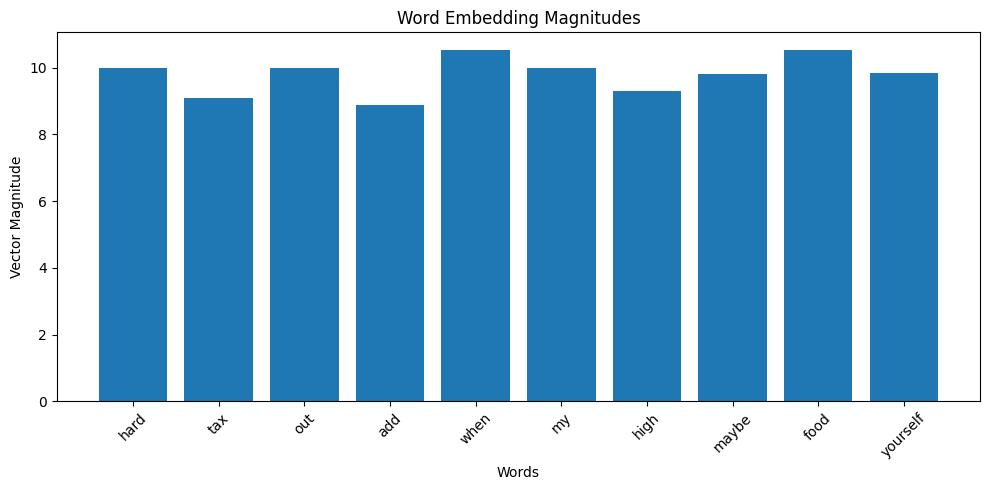


Twitter CBOW Model Saved Successfully!



Enter a word to find similar words:  bad



Embedding:
[-0.01628597  0.03259716  1.3691282  -0.9514262  -0.24591199  0.72105855
 -0.28537703 -1.9604735  -0.37642846  0.84976256  0.08414537  0.5395149
 -0.3968707   2.3535793   0.13815483  0.31002724 -0.4634722   1.1474022
 -0.3012014  -0.30306822 -1.8725971   2.9745603  -2.7801387  -0.33613586
  0.14829934  0.7410003  -0.36759228  0.4106761  -0.72563636  1.2241302
  0.0412722   0.01284519 -1.0333846  -0.6266006   0.81263816  0.74847716
  2.0406804  -0.47178     0.5641445  -1.0396242  -0.36807907  0.4732779
  1.2910821   0.07827509  0.00361365 -0.35042068 -0.2010398   0.3872309
  1.3870541   0.3117584  -1.1643653   0.3181266   1.0278673  -0.6145671
 -1.5981584  -0.26918134 -0.4043357  -0.79314214 -0.8143974   1.1143285
 -0.17639692 -1.6089702  -1.8245931  -0.24589494  0.7054099  -0.3470696
 -0.32797763  1.0173165   1.4667661   0.37043723 -1.5498233  -0.53043604
  0.48064533 -1.2223345  -0.13064702  0.17387761 -0.45016456  0.53735
 -0.15551795  0.09370364 -0.21860848  0.74909794  

In [1]:

# STEP 1: Import Libraries

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from gensim.models import Word2Vec


# STEP 2: Load Twitter Dataset

file_path =  r"F:\lp4\LP IV Updated Datasets\CBOW\twitter_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(df.head())
print("\nColumns:", df.columns)


# STEP 3: Select Tweet Column

# Automatically detect common tweet column names

possible_columns = ['text', 'tweet', 'tweets', 'content']

tweet_column = None

for col in df.columns:
    if col.lower() in possible_columns:
        tweet_column = col
        break

# If no common column is found, use the first text column

if tweet_column is None:
    text_columns = df.select_dtypes(include=['object']).columns

    if len(text_columns) == 0:
        raise ValueError("No text column found in dataset!")

    tweet_column = text_columns[0]

print("\nUsing column:", tweet_column)


# STEP 4: Data Preprocessing

def preprocess_tweet(tweet):

    tweet = str(tweet).lower()

    # Remove URLs
    tweet = re.sub(r'http\S+|www\S+', '', tweet)

    # Remove mentions
    tweet = re.sub(r'@\w+', '', tweet)

    # Remove hashtag symbol but keep the word
    tweet = re.sub(r'#', '', tweet)

    # Remove special characters and numbers
    tweet = re.sub(r'[^a-z\s]', '', tweet)

    # Tokenize tweet
    words = tweet.split()

    return words


df = df.dropna(subset=[tweet_column])

tokenized_tweets = df[tweet_column].apply(preprocess_tweet).tolist()

# Remove empty tweets
tokenized_tweets = [tweet for tweet in tokenized_tweets if len(tweet) > 0]

print("\nTokenized Tweets:")
print(tokenized_tweets[:10])


# STEP 5: Train Word2Vec CBOW Model

model = Word2Vec(
    sentences=tokenized_tweets,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=0,
    epochs=100
)

print("\nCBOW Model Training Completed!")


# STEP 6: Display Word Embeddings

word = model.wv.index_to_key[0]

print("\nSelected Word:", word)

print("\nWord Embedding:")
print(model.wv[word])


# STEP 7: Find Similar Words

print("\nSimilar Words:")

similar_words = model.wv.most_similar(word, topn=5)

for w, score in similar_words:
    print(w, score)


# STEP 8: Calculate Similarity Between Two Words

words = model.wv.index_to_key

if len(words) >= 2:

    word1 = words[0]
    word2 = words[1]

    similarity = model.wv.similarity(word1, word2)

    print("\nSimilarity between", word1, "and", word2)
    print(similarity)


# STEP 9: Visualize Word Embedding Magnitudes

words = model.wv.index_to_key[:10]

vectors = np.array([model.wv[w] for w in words])

plt.figure(figsize=(10, 5))

plt.bar(words, np.linalg.norm(vectors, axis=1))

plt.title("Word Embedding Magnitudes")
plt.xlabel("Words")
plt.ylabel("Vector Magnitude")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# STEP 10: Save the Trained Model

model.save("twitter_cbow_model.model")

print("\nTwitter CBOW Model Saved Successfully!")


# STEP 11: Test with User Input

word = input("\nEnter a word to find similar words: ").lower()

if word in model.wv:

    print("\nEmbedding:")
    print(model.wv[word])

    print("\nMost Similar Words:")

    for w, score in model.wv.most_similar(word, topn=5):
        print(w, score)

else:
    print("Word not found in vocabulary!")
